# Importing the dataset from parquet

In [7]:
import pandas as pd
import numpy as np
import json
from tqdm import tqdm

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)

df = pd.read_parquet("../logs_fixed_board_state.parquet")

df.head()


,log_id,game_session_id,player_id,played_by,board_state,legal_moves,chosen_move,game_status,logged_at,ai_difficulty,mcts_iterations,exploration_constant,visit_counts,action_scores,policy_vector,best_visit_count,best_q_value,move_confidence,branching_factor,explored_actions,mcts_tree_size,rollout_count,rollout_depth_average,rollout_depth_max,mcts_search_duration_ms,ai_latency_ms,outcome,board_state_fixed
0,b845c355-6965-4192-87f6-a227440d5edf,15a3eb8f-28e2-4aea-b4e3-0dc58b933252,bf7308cc-0199-4c2b-badf-82c819fc581b,O,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""EMPT...","[{""col"": 1, ""row"": 0, ""player"": {""mark"": ""O"", ...","{""col"": 0, ""row"": 2, ""bestQValue"": 0.917368421...",IN_PROGRESS,2025-12-01T11:48:08.991819,MEDIUM,1000,0.707107,"""{0,1=10, 1,0=9, 1,2=8, 2,0=950, 2,1=14, 2,2=9}""","""{0,1=0.15, 1,0=0.1111111111111111, 1,2=0.0625...","""{0,1=0.01, 1,0=0.009, 1,2=0.008, 2,0=0.95, 2,...",950,0.917368,0.950,6,6,172,1000,0.227,4,15,15,NONE,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""O""},..."
1,e4148ce5-3435-4b73-a604-0435690a410e,c57cfb6d-f6cb-4cb6-80f3-8351ea9f7b7b,559b50b1-be4e-42de-8bd0-20f422541381,X,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""EMPT...","[{""col"": 1, ""row"": 0, ""player"": {""mark"": ""X"", ...","{""col"": 0, ""row"": 2, ""bestQValue"": 0.872990353...",IN_PROGRESS,2025-12-01T11:48:10.079332,MEDIUM,1000,0.707107,"""{0,1=148, 0,2=209, 1,0=91, 1,2=67, 2,0=311, 2...","""{0,1=0.8040540540540541, 0,2=0.83732057416267...","""{0,1=0.148, 0,2=0.209, 1,0=0.091, 1,2=0.067, ...",311,0.872990,0.311,7,7,800,1000,1.510,6,60,60,NONE,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""O""},..."
2,03d9d5e9-3c15-4d66-b050-a47591c8026d,90431947-b4bd-44dc-9957-7d2ebf9e7f12,f87b4fb6-87fc-4c0b-bf57-dd6314b4b07f,O,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""EMPT...","[{""col"": 1, ""row"": 0, ""player"": {""mark"": ""O"", ...","{""col"": 2, ""row"": 0, ""bestQValue"": 0.921706263...",IN_PROGRESS,2025-12-01T11:48:10.688832,MEDIUM,1000,0.707107,"""{0,1=23, 0,2=926, 1,2=19, 2,0=8, 2,1=11, 2,2=...","""{0,1=0.43478260869565216, 0,2=0.9217062634989...","""{0,1=0.023, 0,2=0.926, 1,2=0.019, 2,0=0.008, ...",926,0.921706,0.926,6,6,166,1000,0.235,5,23,23,NONE,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""O""},..."
3,e232c04a-7e15-40e4-a547-269cf7bfd03c,94333c80-6b8c-49f5-b3ac-ca908db69e28,88f47797-0200-4779-8b47-18a3e34b4861,X,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""EMPT...","[{""col"": 0, ""row"": 0, ""player"": {""mark"": ""X"", ...","{""col"": 2, ""row"": 2, ""bestQValue"": 0.872340425...",IN_PROGRESS,2025-12-01T11:48:11.547821,MEDIUM,1000,0.707107,"""{0,0=211, 0,1=178, 1,0=73, 1,2=111, 2,0=47, 2...","""{0,0=0.8483412322274881, 0,1=0.83426966292134...","""{0,0=0.211, 0,1=0.178, 1,0=0.073, 1,2=0.111, ...",282,0.872340,0.282,7,7,800,1000,1.506,6,44,44,NONE,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""EMPT..."
4,d979d574-040d-4718-8e94-5747bb927d34,58f459b5-15e9-484c-8e01-59347cd5456e,df80b476-53bb-4c8b-96e1-a07915ad6e52,O,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""EMPT...","[{""col"": 0, ""row"": 0, ""player"": {""mark"": ""O"", ...","{""col"": 0, ""row"": 0, ""bestQValue"": 0.397142857...",IN_PROGRESS,2025-12-01T11:48:09.400081,MEDIUM,1000,0.707107,"""{0,0=350, 0,1=86, 0,2=171, 1,0=40, 1,2=48, 2,...","""{0,0=0.39714285714285713, 0,1=0.25, 0,2=0.333...","""{0,0=0.35, 0,1=0.086, 0,2=0.171, 1,0=0.04, 1,...",350,0.397143,0.350,8,8,997,1000,2.679,7,90,90,NONE,"{""board"": [{""col"": 0, ""row"": 0, ""value"": ""EMPT..."


# Define the encoding

In [8]:
ENCODING = {
    "EMPTY": 0,
    "X": 1,
    "O": 2
}

def encode_board(board_state_json):
    """
    board_state_json = string containing {"board": [{"row":...,"col":...,"value":...}, ...]}
    Returns a length-9 numeric list representing row-major order encoding.
    """
    obj = json.loads(board_state_json)
    cells = obj["board"]

    # Sort to ensure correct order (row-major)
    cells_sorted = sorted(cells, key=lambda c: (c["row"], c["col"]))

    encoded = [ENCODING[c["value"]] for c in cells_sorted]
    return encoded


def encode_move(chosen_move_json):
    """
    chosen_move_json → {"row": r, "col": c, ...}
    Returns a class ID from 0 to 8.
    """
    obj = json.loads(chosen_move_json)
    r, c = obj["row"], obj["col"]
    return r * 3 + c


# Apply encoding to the whole dataset

In [9]:
# Encode the board into a 9-element numeric vector
df["board_vector"] = df["board_state_fixed"].apply(encode_board)

# Encode chosen move into a single class
df["move_class"] = df["chosen_move"].apply(encode_move)

df[["board_vector", "move_class"]].head()

,board_vector,move_class
0,"[2, 0, 1, 0, 1, 0, 0, 0, 0]",6
1,"[2, 0, 0, 0, 1, 0, 0, 0, 0]",6
2,"[2, 0, 0, 1, 1, 0, 0, 0, 0]",2
3,"[0, 0, 2, 0, 1, 0, 0, 0, 0]",8
4,"[0, 0, 0, 0, 1, 0, 0, 0, 0]",0


# Convert into arrays

In [10]:
X = np.vstack(df["board_vector"].values)   # shape: (N, 9)
y = df["move_class"].values                # shape: (N,)

# Check class distributions

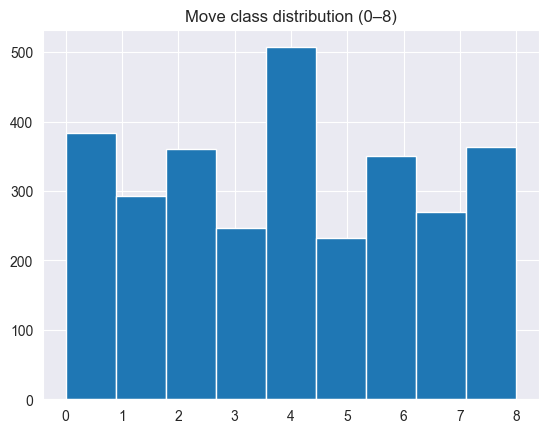

0    383
1    293
2    360
3    247
4    507
5    233
6    351
7    270
8    364
Name: count, dtype: int64

In [11]:
import matplotlib.pyplot as plt

plt.hist(y, bins=9)
plt.title("Move class distribution (0–8)")
plt.show()

pd.Series(y).value_counts().sort_index()


In [12]:
def is_move_legal(board_vec, move_class):
    r = move_class // 3
    c = move_class % 3
    return board_vec[r*3 + c] == 0  # EMPTY = 0

df["legal_check"] = df.apply(lambda row: is_move_legal(row["board_vector"], row["move_class"]), axis=1)

df["legal_check"].value_counts()


legal_check
True    3008
Name: count, dtype: int64

# Build final dataframe

In [13]:
processed = pd.DataFrame({
    "board_vector": list(X),
    "move_class": y,
    "game_session_id": df["game_session_id"],
    "played_by": df["played_by"],
    "logged_at": df["logged_at"]
})

processed.head()


,board_vector,move_class,game_session_id,played_by,logged_at
0,"[2, 0, 1, 0, 1, 0, 0, 0, 0]",6,15a3eb8f-28e2-4aea-b4e3-0dc58b933252,O,2025-12-01T11:48:08.991819
1,"[2, 0, 0, 0, 1, 0, 0, 0, 0]",6,c57cfb6d-f6cb-4cb6-80f3-8351ea9f7b7b,X,2025-12-01T11:48:10.079332
2,"[2, 0, 0, 1, 1, 0, 0, 0, 0]",2,90431947-b4bd-44dc-9957-7d2ebf9e7f12,O,2025-12-01T11:48:10.688832
3,"[0, 0, 2, 0, 1, 0, 0, 0, 0]",8,94333c80-6b8c-49f5-b3ac-ca908db69e28,X,2025-12-01T11:48:11.547821
4,"[0, 0, 0, 0, 1, 0, 0, 0, 0]",0,58f459b5-15e9-484c-8e01-59347cd5456e,O,2025-12-01T11:48:09.400081


In [14]:
processed.to_parquet("../processed_policy_dataset.parquet")

print("Saved processed dataset as ../processed_policy_dataset.parquet")


Saved processed dataset as ../processed_policy_dataset.parquet
